<a href="https://colab.research.google.com/github/TOMMY920710/an-lisis-de-datos--Python-/blob/main/an%C3%A1lisis_datos_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd

from google.colab import drive

drive.mount("/content/drive")

# carga de los conjuntos de datos

df_clientes = pd.read_csv("/content/drive/MyDrive/pre-entrega/clientes.csv")
df_marketing =pd.read_csv("/content/drive/MyDrive/pre-entrega/marketing.csv")
df_ventas = pd.read_csv("/content/drive/MyDrive/pre-entrega/ventas.csv")


#Realizar un script básico que calcule las ventas mensuales utilizando variables y operadores.



# squitarigno $ y cambiar tipo de dato

df_ventas["precio"] =  df_ventas["precio"].str.replace("$","",regex=False)


df_ventas["precio"] = df_ventas["precio"].astype(float)

#calcular total de ventas

df_ventas["ventas_totales"] = df_ventas["precio"] * df_ventas["cantidad"]

df_ventas["ventas_totales"] = round(df_ventas["ventas_totales"],2)

# datos de la fechas sean un tipo de dato fecha

df_ventas["fecha_venta"] = pd.to_datetime(df_ventas["fecha_venta"],dayfirst=True)

# crear columna mes

df_ventas["mes"] = df_ventas["fecha_venta"].dt.to_period("M")

# crear grupos de ventas y sumar totales

ventas_mensuales = df_ventas.groupby("mes")["ventas_totales"].sum()

print("ventas mensuales")
print(ventas_mensuales)

#3- Estructuras dae datos: Desarrollar un programa que almacene los datos de ventas (producto, precio, cantidad).
#Decidir si conviene utilizar diccionarios o listas.

ventas_lista = df_ventas[["id_venta","producto","precio","cantidad"]].to_dict("records")

ventas_lista

#4- Introducción a Pandas: realizar un análisis exploratorio inicial de los DataFrames.

print(df_clientes)
print(df_marketing)
print(df_ventas)



#5- Calidad de datos: Identificar valores nulos y duplicados en los conjuntos de datos. Documentar el estado inicial de los datos.

#valores duplicados
duplicados_clientes = df_clientes.duplicated().sum()
duplicados_marketing =df_marketing.duplicated().sum()
duplicados_ventas =df_ventas.duplicated().sum()

print("duplicados-------------------------------------------------------------------------------")
print("filas duplicadas en clientes" , duplicados_clientes)
print("filas duplicadas en marketing" , duplicados_marketing)
print("filas duplicadas en ventas" , duplicados_ventas)

#valores nulos

nulos_marketing = df_marketing.isnull().sum()
nulos_clientes = df_clientes.isnull().sum()
nulos_ventas = df_ventas.isnull().sum()

print("nulos -------------------------------------------------------------------------------------- ")

print("valors nulos de clientes ", nulos_clientes)
print("valors nulos de marketing ", nulos_marketing)
print("valors nulos de ventas ", nulos_ventas)

# Etapa 2: preprocesamiento y limpieza de datos (Clases 5 a 8)

#1- Limpieza de datos: Limpiar el conjunto de datos eliminando duplicados y caracteres no deseados. Documentar el proceso y los resultados.

clientes_limpios = df_clientes.copy()
marketing_limpios = df_marketing.copy()
ventas_limpios = df_ventas.copy()

#eliminar duplicados

ventas_limpios = ventas_limpios.drop_duplicates()
print("elimar duplicados--------------------------------------------------------------------------------------------------------")
print("registros original de ventas : " , len(df_ventas))
print("registros sin duplicados: " ,len(ventas_limpios) )


#eliminar caracateres no deseados (espacios)

for df in [clientes_limpios,marketing_limpios,ventas_limpios]:
  for columna in df.select_dtypes(include ="object").columns:
    df[columna] = df[columna].str.strip()

marketing_limpios

#Aplicar filtros y transformaciones para crear una tabla de ventas que muestre solo los productos con alto rendimiento.

#agrupar por porducto
ventas_producto = df_ventas.groupby("producto")["ventas_totales"].sum().reset_index()

#umbral

umbral = ventas_producto["ventas_totales"].quantile(0.75)

print(umbral )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ventas mensuales
mes
2024-01    129604.99
2024-02    118672.44
2024-03    136779.15
2024-04    144380.10
2024-05    143727.25
2024-06    108480.17
2024-07    116229.97
2024-08    119680.15
2024-09    115787.85
2024-10    112117.13
2024-11    119951.79
2024-12    117631.94
Freq: M, Name: ventas_totales, dtype: float64
     id_cliente               nombre  edad         ciudad  ingresos
0             1      Aloysia Screase    44  Mar del Plata  42294.68
1             2  Kristina Scaplehorn    25        Posadas  24735.04
2             3       Filip Castagne    50    Resistencia  35744.85
3             4          Liuka Luard    39   Bahía Blanca  27647.96
4             5        Dore Cockshtt    28        Rosario  28245.65
..          ...                  ...   ...            ...       ...
562         563        Dione Forsyde    29        Posadas  26757.73
563     

In [8]:
#Aplicar filtros y transformaciones para crear una tabla de ventas que muestre solo los productos con alto rendimiento.

#agrupar por porducto
ventas_producto = df_ventas.groupby("producto")["ventas_totales"].sum().reset_index()

#umbral

umbral = ventas_producto["ventas_totales"].quantile(0.75)

print(umbral )

#productos mas vendidos

productos_mas_vendidos = ventas_producto[ventas_producto["ventas_totales"]>=umbral]

# tabla alto rendimiento

ventas_alto_rendimiento = df_ventas[df_ventas["producto"].isin(productos_mas_vendidos["producto"])]

ventas_alto_rendimiento


#3- Agregación: Resumir las ventas por categoría de producto y analizar los ingresos generados.

ventas_categoria = pd.pivot_table(
    df_ventas,
    index ="categoria",
    values="ventas_totales",
    aggfunc ="sum"
)

ventas_categoria

"""
estado inicial conjunto de datos

conjuto ventas = 45 duplicados
"""

# combinamos

datos_integrados = pd.merge(df_ventas,df_marketing,on="producto",how="inner")


datos_integrados



51311.8375


,id_venta,producto,precio,cantidad,fecha_venta,categoria,ventas_totales,mes,id_campanha,canal,costo,fecha_inicio,fecha_fin
0,792,Cuadro decorativo,69.94,5.0,2024-01-02,Decoración,349.70,2024-01,1,RRSS,5.27,27/04/2024,04/06/2024
1,792,Cuadro decorativo,69.94,5.0,2024-01-02,Decoración,349.70,2024-01,31,Email,5.28,15/08/2024,12/09/2024
2,792,Cuadro decorativo,69.94,5.0,2024-01-02,Decoración,349.70,2024-01,61,TV,5.30,05/11/2024,23/12/2024
3,811,Lámpara de mesa,105.10,5.0,2024-01-02,Decoración,525.50,2024-01,32,Email,5.54,28/03/2024,20/04/2024
4,811,Lámpara de mesa,105.10,5.0,2024-01-02,Decoración,525.50,2024-01,2,RRSS,5.88,30/05/2024,29/06/2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9100,2913,Smartphone,99.85,7.0,2024-12-30,Electrónica,698.95,2024-12,51,Email,4.65,28/05/2024,15/06/2024
9101,2913,Smartphone,99.85,7.0,2024-12-30,Electrónica,698.95,2024-12,81,TV,4.78,28/09/2024,24/10/2024
9102,2930,Consola de videojuegos,55.47,6.0,2024-12-30,Electrónica,332.82,2024-12,50,Email,4.97,03/05/2024,28/05/2024
9103,2930,Consola de videojuegos,55.47,6.0,2024-12-30,Electrónica,332.82,2024-12,20,RRSS,3.16,15/07/2024,03/08/2024


        precio  cantidad  ventas_totales
count  3033.00   3033.00         3033.00
mean     75.29      6.50          488.97
std      28.73      3.46          334.59
min      26.00      1.00           26.30
25%      50.02      3.00          220.50
50%      75.27      7.00          418.05
75%     100.04      9.00          708.89
max     124.97     12.00         1488.12


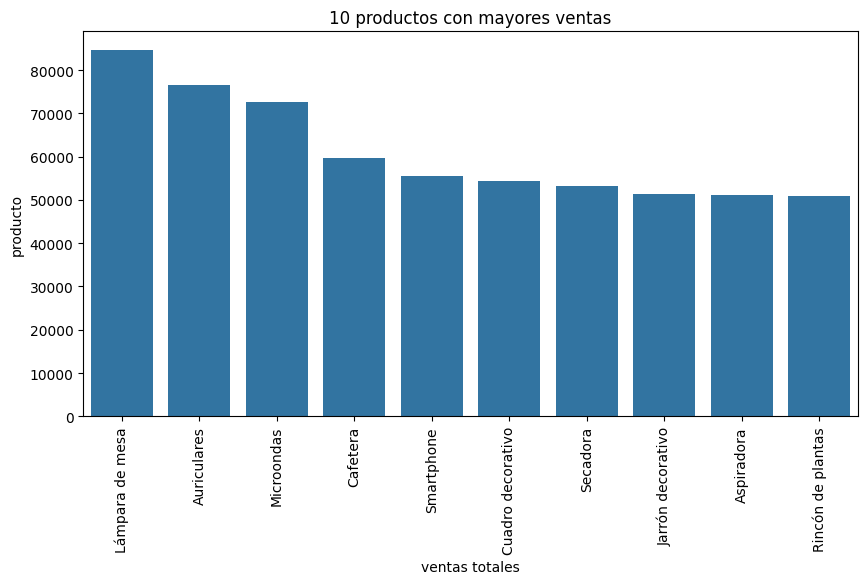

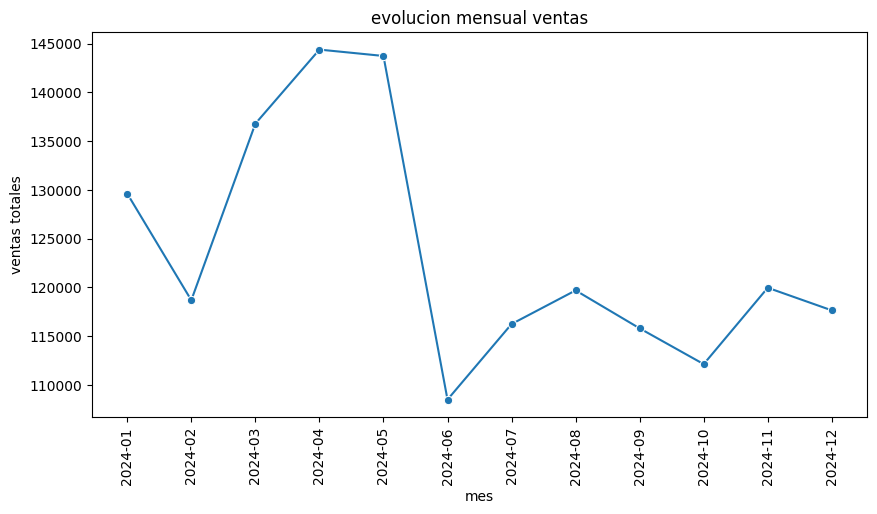

,ventas_totales
producto,
Lámpara de mesa,84699.15
Auriculares,76468.44
Microondas,72562.89
Cafetera,59669.54
Smartphone,55615.64
Cuadro decorativo,54297.60
Secadora,53214.24
Jarrón decorativo,51401.51
Aspiradora,51042.82


Matriz de correlación:


,precio,cantidad,ventas_totales
precio,1.000000,-0.001501,0.558799
cantidad,-0.001501,1.000000,0.773435
ventas_totales,0.558799,0.773435,1.000000


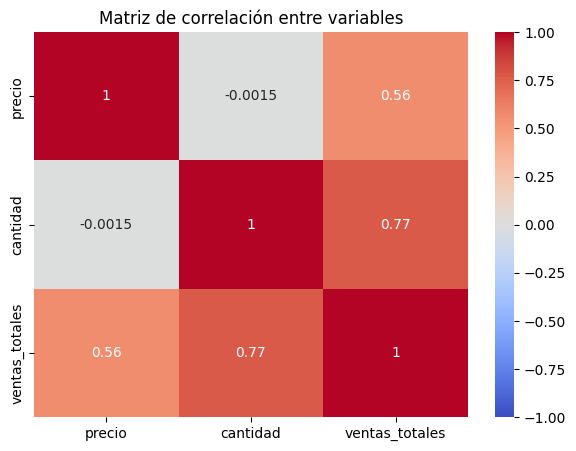

relacion precio y cantidad : -0.0015012733324898193


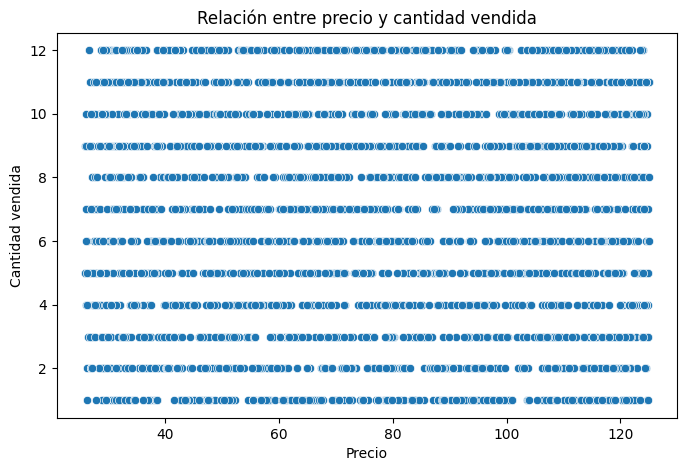

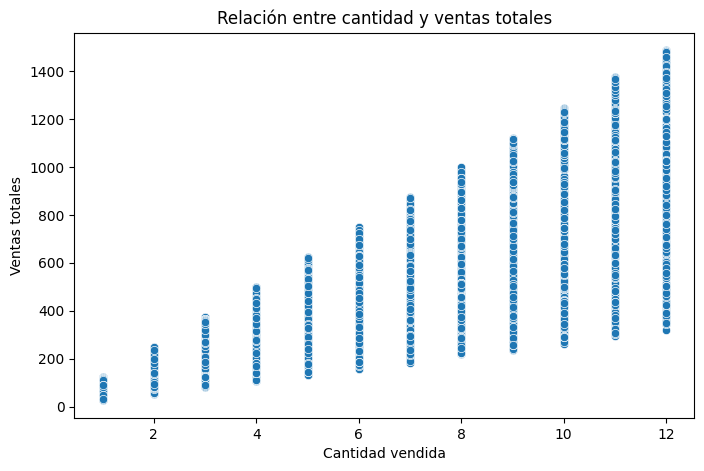

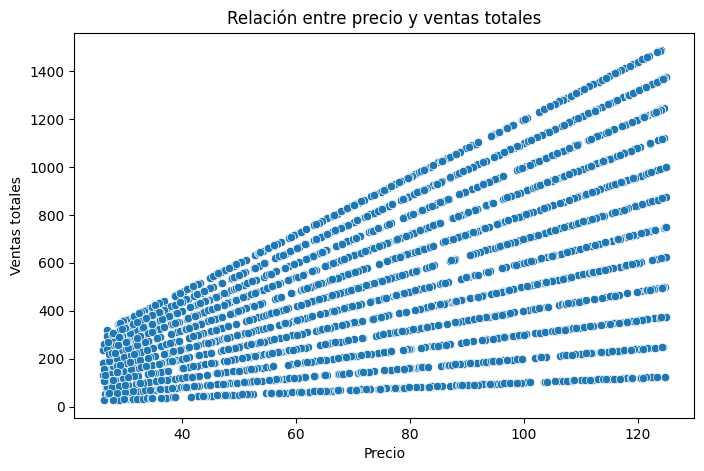

In [9]:
estadisticas = df_ventas[["precio","cantidad","ventas_totales"]].describe()

print(round(estadisticas,2))

import matplotlib.pyplot as plt
import seaborn as sns

#productos con mayores ventas

ventas_por_producto = df_ventas.groupby("producto")["ventas_totales"].sum()

ventas_por_producto = ventas_por_producto.sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.barplot(
    y=ventas_por_producto.head(10).values,
    x=ventas_por_producto.head(10).index
)

plt.title("10 productos con mayores ventas")
plt.xlabel("ventas totales")
plt.ylabel("producto")
plt.xticks(rotation =90)

plt.show()


#evolucionde las ventas por mes

ventas_por_mes = df_ventas.groupby("mes")["ventas_totales"].sum()

plt.figure(figsize = (10,5))

sns.lineplot(
    x=ventas_por_mes.index.astype(str),
    y=ventas_por_mes.values,
    marker="o"
)

plt.title("evolucion mensual ventas")
plt.xlabel("mes")
plt.ylabel("ventas totales")
plt.xticks(rotation =90)

plt.show()

display(ventas_por_producto)



# ==========================================
# ENTREGA FINAL - 3. CORRELACIÓN
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Calcular la correlación entre las variables numéricas
correlacion = df_ventas[["precio", "cantidad", "ventas_totales"]].corr()

# Mostrar la matriz de correlación
print("Matriz de correlación:")
display(correlacion)


# ==========================================
# GRÁFICO 1: MATRIZ DE CORRELACIÓN
# ==========================================

# Crear el gráfico
plt.figure(figsize=(7, 5))

# Mostrar las correlaciones con colores y valores
sns.heatmap(correlacion, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

# Agregar título
plt.title("Matriz de correlación entre variables")

# Mostrar el gráfico
plt.show()


# ==========================================
# GRÁFICO 2: PRECIO Y CANTIDAD VENDIDA
# ==========================================

print("relacion precio y cantidad :", df_ventas["precio"].corr(df_ventas["cantidad"]))

# Crear el gráfico de dispersión
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_ventas, x="precio", y="cantidad")

# Agregar título y nombres a los ejes
plt.title("Relación entre precio y cantidad vendida")
plt.xlabel("Precio")
plt.ylabel("Cantidad vendida")

# Mostrar el gráfico
plt.show()


# ==========================================
# GRÁFICO 3: CANTIDAD Y VENTAS TOTALES
# ==========================================

plt.figure(figsize=(8, 5))

# Comparar cantidad vendida y total de la venta
sns.scatterplot(data=df_ventas, x="cantidad", y="ventas_totales")

plt.title("Relación entre cantidad y ventas totales")
plt.xlabel("Cantidad vendida")
plt.ylabel("Ventas totales")
plt.show()


# ==========================================
# GRÁFICO 4: PRECIO Y VENTAS TOTALES
# ==========================================

plt.figure(figsize=(8, 5))

# Comparar precio y total de la venta
sns.scatterplot(data=df_ventas, x="precio", y="ventas_totales")

plt.title("Relación entre precio y ventas totales")
plt.xlabel("Precio")
plt.ylabel("Ventas totales")
plt.show()



información de ventas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3035 entries, 0 to 3034
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id_venta        3035 non-null   int64         
 1   producto        3035 non-null   object        
 2   precio          3033 non-null   float64       
 3   cantidad        3033 non-null   float64       
 4   fecha_venta     3035 non-null   datetime64[ns]
 5   categoria       3035 non-null   object        
 6   ventas_totales  3033 non-null   float64       
 7   mes             3035 non-null   period[M]     
dtypes: datetime64[ns](1), float64(3), int64(1), object(2), period[M](1)
memory usage: 189.8+ KB
información de marketing:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_campanha   90 non-null     int64

,id_venta,precio,cantidad,fecha_venta,ventas_totales
count,3035.000000,3033.000000,3033.000000,3035,3033.000000
mean,1499.851400,75.289034,6.496538,2024-06-25 20:51:09.785832192,488.968985
min,1.000000,26.000000,1.000000,2024-01-02 00:00:00,26.300000
25%,748.500000,50.020000,3.000000,2024-03-28 00:00:00,220.500000
50%,1502.000000,75.270000,7.000000,2024-06-21 00:00:00,418.050000
75%,2249.500000,100.040000,9.000000,2024-09-25 00:00:00,708.890000
max,3000.000000,124.970000,12.000000,2024-12-30 00:00:00,1488.120000
std,866.465379,28.734666,3.457250,NaN,334.594511


estadisticas de marketing:


,id_campanha,costo
count,90.000000,90.000000
mean,45.500000,4.928667
std,26.124701,0.947750
min,1.000000,2.950000
25%,23.250000,4.372500
50%,45.500000,4.900000
75%,67.750000,5.562500
max,90.000000,7.390000


estadisticas de clientes:


,id_cliente,edad,ingresos
count,567.000000,567.000000,567.000000
mean,284.000000,37.940035,34668.739012
std,163.823075,10.202885,12974.531446
min,1.000000,20.000000,170.290000
25%,142.500000,30.000000,26015.240000
50%,284.000000,37.000000,35066.830000
75%,425.500000,43.000000,42457.100000
max,567.000000,81.000000,88053.010000


valores nulos en ventas:
id_venta          0
producto          0
precio            2
cantidad          2
fecha_venta       0
categoria         0
ventas_totales    2
mes               0
dtype: int64
valores nulos en marketing:
id_campanha     0
producto        0
canal           0
costo           0
fecha_inicio    0
fecha_fin       0
dtype: int64
valores nulos en clientes:
id_cliente    0
nombre        0
edad          0
ciudad        0
ingresos      0
dtype: int64
filas duplicadas en ventas: 35
filas duplicadas en marketing: 0
filas duplicadas en clientes: 0
filas de ventas_limpios: 2998
filas de marketing_limpios: 90
filas de clientes_limpios: 567


,id_venta,producto,precio,cantidad,fecha_venta,categoria,ventas_totales,mes
0,792,Cuadro decorativo,69.94,5.0,2024-01-02,Decoración,349.70,2024-01
1,811,Lámpara de mesa,105.10,5.0,2024-01-02,Decoración,525.50,2024-01
2,1156,Secadora,97.96,3.0,2024-01-02,Electrodomésticos,293.88,2024-01
3,1372,Heladera,114.35,8.0,2024-01-02,Electrodomésticos,914.80,2024-01
4,1546,Secadora,106.21,4.0,2024-01-02,Electrodomésticos,424.84,2024-01


,id_venta,producto,precio,cantidad,fecha_venta,categoria,ventas_totales,mes,id_campanha,canal,costo,fecha_inicio,fecha_fin
0,792,Cuadro decorativo,69.94,5.0,2024-01-02,Decoración,349.7,2024-01,1,RRSS,5.27,2024-04-27,2024-06-04
1,792,Cuadro decorativo,69.94,5.0,2024-01-02,Decoración,349.7,2024-01,31,Email,5.28,2024-08-15,2024-09-12
2,792,Cuadro decorativo,69.94,5.0,2024-01-02,Decoración,349.7,2024-01,61,TV,5.30,2024-11-05,2024-12-23
3,811,Lámpara de mesa,105.10,5.0,2024-01-02,Decoración,525.5,2024-01,32,Email,5.54,2024-03-28,2024-04-20
4,811,Lámpara de mesa,105.10,5.0,2024-01-02,Decoración,525.5,2024-01,2,RRSS,5.88,2024-05-30,2024-06-29


,producto,ventas_totales
19,Lámpara de mesa,82276.38
3,Auriculares,74175.58
20,Microondas,72562.89
5,Cafetera,59607.31
9,Cuadro decorativo,54297.60
27,Smartphone,54132.44
25,Secadora,52115.45
16,Jarrón decorativo,51130.88
4,Batidora,50979.20
24,Rincón de plantas,50456.45


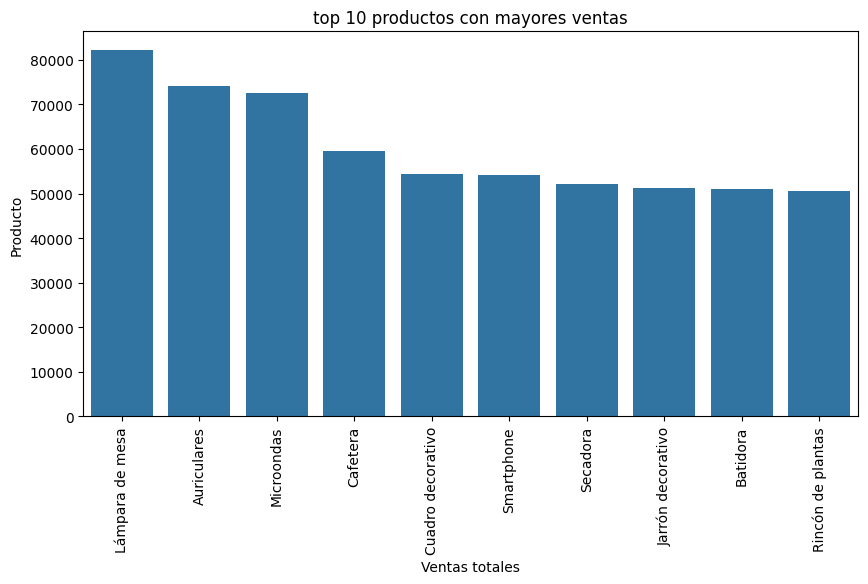

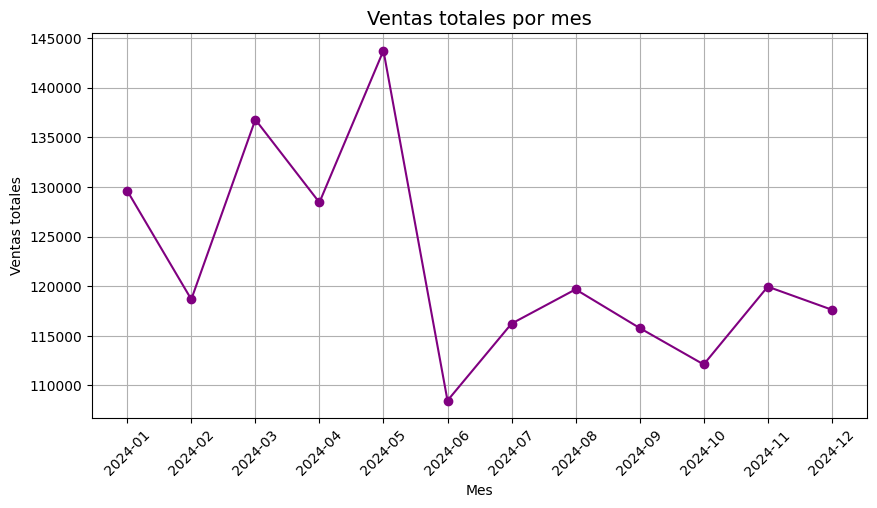

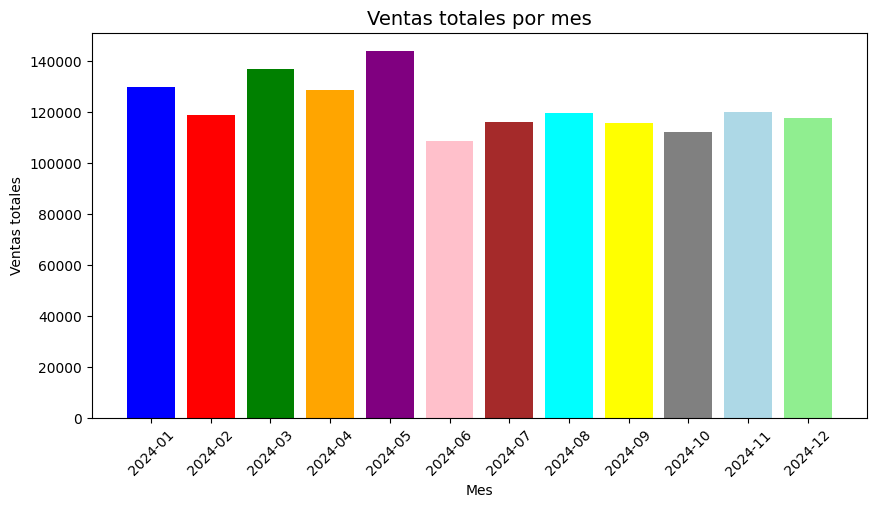

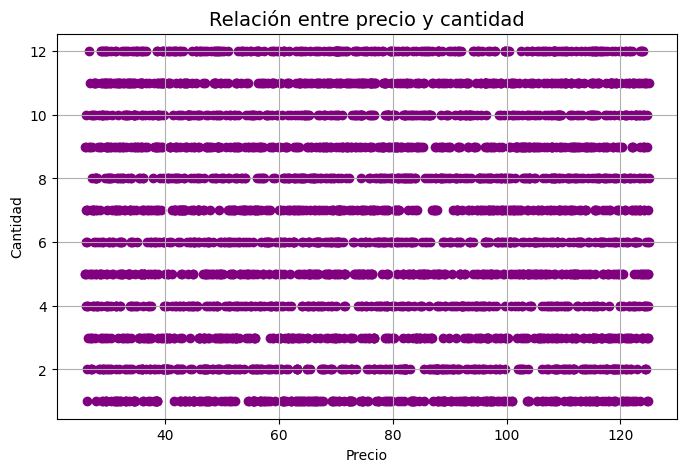

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns


#  EXPLORACION INICIAL DE LOS DATOS


print("información de ventas:")
df_ventas.info()

print("información de marketing:")
df_marketing.info()

print("información de clientes:")
df_clientes.info()

#  estadisticas descriptivas
print("estadisticas de ventas:")
display(df_ventas.describe())

print("estadisticas de marketing:")
display(df_marketing.describe())

print("estadisticas de clientes:")
display(df_clientes.describe())

#  valores nulos
print("valores nulos en ventas:")
print(df_ventas.isnull().sum())

print("valores nulos en marketing:")
print(df_marketing.isnull().sum())

print("valores nulos en clientes:")
print(df_clientes.isnull().sum())

#  filas duplicadas
print("filas duplicadas en ventas:", df_ventas.duplicated().sum())

print("filas duplicadas en marketing:", df_marketing.duplicated().sum())

print("filas duplicadas en clientes:", df_clientes.duplicated().sum())




#  LIMPIEZA DE DATOS


#  copias para los DataFrames originales
ventas_limpios = df_ventas.copy()
marketing_limpios = df_marketing.copy()
clientes_limpios = df_clientes.copy()

# eliminar duplicados
ventas_limpios = ventas_limpios.drop_duplicates()
marketing_limpios = marketing_limpios.drop_duplicates()
clientes_limpios = clientes_limpios.drop_duplicates()

# eliminar valores nulos
ventas_limpios = ventas_limpios.dropna()
marketing_limpios = marketing_limpios.dropna()
clientes_limpios = clientes_limpios.dropna()

# eliminar espacios  en las columnas de texto
for df in [ventas_limpios, marketing_limpios, clientes_limpios]:
    for columna in df.select_dtypes(include="object").columns:
        df[columna] = df[columna].str.strip()

# ver  cantidad de filas
print("filas de ventas_limpios:", len(ventas_limpios))
print("filas de marketing_limpios:", len(marketing_limpios))
print("filas de clientes_limpios:", len(clientes_limpios))



# 5. TRANSFORMACION DE DATOS


# convertir las columnas de  fechas en formato fecha
ventas_limpios["fecha_venta"] = pd.to_datetime(ventas_limpios["fecha_venta"], dayfirst=True)

marketing_limpios["fecha_inicio"] = pd.to_datetime(marketing_limpios["fecha_inicio"], dayfirst=True)

marketing_limpios["fecha_fin"] = pd.to_datetime(marketing_limpios["fecha_fin"], dayfirst=True)



# convertir cantidad a número
ventas_limpios["cantidad"] = ventas_limpios["cantidad"].astype(float)



# calcular total de cada venta
ventas_limpios["ventas_totales"] = (ventas_limpios["precio"] * ventas_limpios["cantidad"])

# crear una columna con el mes de cada venta
ventas_limpios["mes"] = ventas_limpios["fecha_venta"].dt.to_period("M")


display(ventas_limpios.head())



#  CONSOLIDACION DE DATOS


# combinar ventas y marketing utilizando el producto
df_consolidado = pd.merge(ventas_limpios,marketing_limpios,on="producto",how="left")


display(df_consolidado.head())



#  AGRUPACION Y AGREGACION


# agrupar las ventas totales por producto
resumen_productos = ventas_limpios.groupby("producto")["ventas_totales"].sum().reset_index()

resumen_productos = resumen_productos.sort_values(by="ventas_totales",ascending=False)

display(resumen_productos)



# GRÁFICO: TOP 10 PRODUCTOS



top_productos = resumen_productos.head(10)


plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_productos,
    x="producto",
    y="ventas_totales"
)

plt.title("top 10 productos con mayores ventas")
plt.xlabel("Ventas totales")
plt.ylabel("Producto")
plt.xticks(rotation=90)

plt.show()


# ==========================================
# 1. VISUALIZACIÓN CON MATPLOTLIB
# ==========================================

# ------------------------------------------
# GRÁFICO 1: VENTAS POR MES - LÍNEAS
# ------------------------------------------

# Agrupar las ventas totales por mes
ventas_por_mes = ventas_limpios.groupby("mes")["ventas_totales"].sum()

plt.figure(figsize=(10, 5))

plt.plot(
    ventas_por_mes.index.astype(str),
    ventas_por_mes.values,
    marker="o",
    color="purple"
)

plt.title("Ventas totales por mes", fontsize=14)
plt.xlabel("Mes")
plt.ylabel("Ventas totales")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()


# ------------------------------------------
# GRÁFICO 2: VENTAS POR MES - BARRAS
# ------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    ventas_por_mes.index.astype(str),
    ventas_por_mes.values,
    color=[
        "blue", "red", "green", "orange",
        "purple", "pink", "brown", "cyan",
        "yellow", "gray", "lightblue", "lightgreen"
    ]
)

plt.title("Ventas totales por mes", fontsize=14)
plt.xlabel("Mes")
plt.ylabel("Ventas totales")
plt.xticks(rotation=45)

plt.show()


# ------------------------------------------
# GRÁFICO 3: PRECIO Y CANTIDAD - DISPERSIÓN
# ------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    ventas_limpios["precio"],
    ventas_limpios["cantidad"],
    color="purple"
)

plt.title("Relación entre precio y cantidad", fontsize=14)
plt.xlabel("Precio")
plt.ylabel("Cantidad")
plt.grid(True)

plt.show()





## 1. Limpieza y Tratamiento de Datos

* **Duplicados:** Se eliminaron 35 filas duplicadas en el archivo de ventas para evitar contar dos veces los mismos ingresos.
* **Valores Nulos:** Se eliminaron 2 filas que contenían valores vacíos en precio y cantidad. Representan el 0.07% de los datos (2,998 registros finales), por lo que quitarlas no afecta los resultados y asegura que los cálculos sean precisos.
* **Normalización:** Se quitaron espacios en blanco sobrantes en las columnas de texto y se formatearon los valores numéricos y las fechas correctamente.

---

## 2.  Integración

### Ventas + Marketing

* **Fundamento:** Ambos archivos comparten la columna producto. Se utilizó una unión de tipo left para conservar el total de transacciones de ventas y agregarles la información de costo y canal publicitario correspondiente.


### Análisis independiente de Clientes

* **Incompatibilidad de claves:** El archivo ventas.csv no dispone de una columna id_cliente. Realizar un cruce forzado sin esta clave generaría combinaciones incorrectas o datos duplicados. Por este motivo se recomienda,que el conjunto de **Clientes se puede analizar de manera autónoma** para evaluar variables demográficas (edad, ciudad e ingresos).

---

## 3. Hallazgos Clave

* **Top 3 de productos en facturación:**
1. Lámpara de mesa: más de $82,000

2. Auriculares: aproximado a $74,100

3. Microondas: aproximado a $72,500







grafico 1

In [17]:
# ==========================================
# DASHBOARD INTERACTIVO CON PLOTLY
# ==========================================

import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go


# ------------------------------------------
# 1. AGRUPAR VENTAS POR MES
# ------------------------------------------

ventas_por_mes = (
    ventas_limpios
    .groupby("mes")["ventas_totales"]
    .sum()
    .reset_index()
)

ventas_por_mes["mes"] = ventas_por_mes["mes"].astype(str)


# ------------------------------------------
# 2. OBTENER TOP 10 PRODUCTOS
# ------------------------------------------

top_productos = (
    ventas_limpios
    .groupby("producto")["ventas_totales"]
    .sum()
    .reset_index()
    .sort_values("ventas_totales", ascending=False)
    .head(10)
)


# ------------------------------------------
# 3. CREAR DASHBOARD
# ------------------------------------------

fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=(
        "Ventas Totales por Mes",
        "Top 10 Productos por Ventas"
    ),
    vertical_spacing=0.18
)


# Gráfico de líneas
fig.add_trace(
    go.Scatter(
        x=ventas_por_mes["mes"],
        y=ventas_por_mes["ventas_totales"],
        mode="lines+markers",
        name="Ventas mensuales"
    ),
    row=1,
    col=1
)


# Gráfico de barras
fig.add_trace(
    go.Bar(
        x=top_productos["producto"].astype(str),
        y=top_productos["ventas_totales"],
        name="Top 10 productos"
    ),
    row=2,
    col=1
)


# ------------------------------------------
# 4. PERSONALIZAR DASHBOARD
# ------------------------------------------

fig.update_layout(
    title="Dashboard de Análisis de Ventas",
    template="plotly_white",
    height=850,
    showlegend=False
)

fig.update_xaxes(title_text="Mes", row=1, col=1)
fig.update_yaxes(title_text="Ventas totales", row=1, col=1)

fig.update_xaxes(title_text="Producto", row=2, col=1)
fig.update_yaxes(title_text="Ventas totales", row=2, col=1)


# ------------------------------------------
# 5. MOSTRAR DASHBOARD
# ------------------------------------------

fig.show()

grafico 2

In [29]:
# ==========================================
# DASHBOARD INTERACTIVO DE VENTAS
# ==========================================

import plotly.graph_objects as go
from plotly.subplots import make_subplots


# ------------------------------------------
# 1. PREPARAR LOS DATOS
# ------------------------------------------




ventas_por_mes = (
    ventas_limpios
    .groupby("mes")["ventas_totales"]
    .sum()
    .reset_index()
)
ventas_por_mes["mes"] = ventas_por_mes["mes"].astype(str)

ventas_torta = (
    ventas_limpios
    .groupby("categoria")["ventas_totales"]
    .sum()
    .reset_index()
    .sort_values("ventas_totales", ascending=False)
    .head(6)  # Muestra hasta las 6 principales para que la torta no se sature
)

top_productos = (
    ventas_limpios
    .groupby("producto")["ventas_totales"]
    .sum()
    .reset_index()
    .sort_values("ventas_totales", ascending=False)
    .head(10)
)

# Indicadores
total_ventas = ventas_limpios["ventas_totales"].sum()
cantidad_registros = len(ventas_limpios)
cantidad_productos = ventas_limpios["producto"].nunique()


# ------------------------------------------
# 2. DEFINIR COLORES
# ------------------------------------------

azul_oscuro = "#153244"
azul = "#2878B5"
celeste = "#8DE2D6"
turquesa = "#20A89E"
naranja = "#FFB547"
gris_fondo = "#F2F5F8"


# ------------------------------------------
# 3. CREAR ESTRUCTURA DEL DASHBOARD
# ------------------------------------------

fig = make_subplots(
    rows=3,
    cols=6,
    specs=[
        [
            {"type": "indicator", "colspan": 2}, None,
            {"type": "indicator", "colspan": 2}, None,
            {"type": "indicator", "colspan": 2}, None
        ],
        [
            {"colspan": 6}, None, None, None, None, None
        ],
        [
            {"type": "domain", "colspan": 3}, None, None,
            {"type": "xy", "colspan": 3}, None, None
        ]
    ],
    subplot_titles=(
        "VENTAS TOTALES",
        "CANTIDAD DE VENTAS",
        "PRODUCTOS DIFERENTES",
        "Evolución de ventas mensuales",
        "Distribución por categoria",
        "Top 10 productos con mayores ventas"
    ),
    row_heights=[0.20, 0.40, 0.40],
    vertical_spacing=0.14,
    horizontal_spacing=0.06
)


# ------------------------------------------
# 4. AGREGAR INDICADORES
# ------------------------------------------

fig.add_trace(
    go.Indicator(
        mode="number",
        value=total_ventas,
        number={
            "prefix": "$",
            "valueformat": ",.2f",
            "font": {"size": 30, "color": azul}
        },
        title={"text": "Facturación total"}
    ),
    row=1, col=1
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=cantidad_registros,
        number={
            "valueformat": ",.0f",
            "font": {"size": 30, "color": turquesa}
        },
        title={"text": "Operaciones registradas"}
    ),
    row=1, col=3
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=cantidad_productos,
        number={
            "valueformat": ",.0f",
            "font": {"size": 30, "color": naranja}
        },
        title={"text": "Productos diferentes"}
    ),
    row=1, col=5
)


# ------------------------------------------
# 5. GRÁFICO DE VENTAS MENSUALES
# ------------------------------------------

fig.add_trace(
    go.Scatter(
        x=ventas_por_mes["mes"],
        y=ventas_por_mes["ventas_totales"],
        mode="lines+markers",
        name="Ventas mensuales",
        line={"color": azul, "width": 4},
        marker={
            "size": 9,
            "color": celeste,
            "line": {"color": azul, "width": 2}
        },
        fill="tozeroy",
        fillcolor="rgba(40, 120, 181, 0.10)",
        hovertemplate="<b>Mes:</b> %{x}<br><b>Ventas:</b> $%{y:,.2f}<extra></extra>"
    ),
    row=2, col=1
)


# ------------------------------------------
# 6A. GRÁFICO DE TORTA (IZQUIERDA)
# ------------------------------------------

fig.add_trace(
    go.Pie(
        labels=ventas_torta["categoria"],
        values=ventas_torta["ventas_totales"],
        hole=0.45,
        marker_colors=[azul_oscuro, azul, turquesa, celeste, naranja, "#E77D55"],
        textinfo="percent+label",
        hovertemplate="<b>%{label}:</b> $%{value:,.2f} (%{percent})<extra></extra>"
    ),
    row=3, col=1
)


# ------------------------------------------
# 6B. GRÁFICO TOP 10 PRODUCTOS (DERECHA)
# ------------------------------------------

colores_barras = [
    azul_oscuro, azul, "#398CC5", "#53A5CE",
    turquesa, "#42B9A9", "#70C9B6", naranja,
    "#F5A15D", "#E77D55"
]

fig.add_trace(
    go.Bar(
        x=top_productos["producto"],
        y=top_productos["ventas_totales"],
        name="Top 10 productos",
        marker_color=colores_barras,
        hovertemplate="<b>Producto:</b> %{x}<br><b>Ventas:</b> $%{y:,.2f}<extra></extra>"
    ),
    row=3, col=4
)


# ------------------------------------------
# 7. CONFIGURACIÓN DEL LAYOUT
# ------------------------------------------

fig.update_layout(
    title={
        "text": "ANÁLISIS DE VENTAS | DASHBOARD",
        "x": 0.5,
        "y": 0.96,
        "font": {"size": 24, "color": azul_oscuro}
    },
    template="plotly_white",
    paper_bgcolor=gris_fondo,
    plot_bgcolor="white",
    height=1050,
    showlegend=False,
    font={"family": "Arial", "color": azul_oscuro, "size": 12},
    margin={"t": 120, "b": 70, "l": 60, "r": 40}
)


# ------------------------------------------
# 8. PERSONALIZAR EJES
# ------------------------------------------

fig.update_xaxes(title_text="Mes", row=2, col=1, showgrid=False)
fig.update_yaxes(title_text="Ventas ($)", row=2, col=1, gridcolor="#E5EAF0")

fig.update_xaxes(title_text="Producto", row=3, col=4, showgrid=False)
fig.update_yaxes(title_text="Ventas ($)", row=3, col=4, gridcolor="#E5EAF0")


# ------------------------------------------
# 9. MOSTRAR DASHBOARD
# ------------------------------------------

fig.show()